# Deep Learning Project 1 — Knowledge Distillation: 53M Teacher → 4.8M ResNet Student

This notebook trains three models on the Kaggle CIFAR-10 data and compares them on the same validation split:

| Phase | Model | Params | What it is |
|---|---|---|---|
| 1 | **Student (baseline)** | 4.80M | The exact ResNet from `DL_Project1_ResNet_CIFAR10.ipynb` (C = 80/160/320, B = 2/3/2) trained normally |
| 2 | **Teacher** | ~53M (≈11× student) | Same `ResNetCIFAR` class, scaled to C = 192/384/768, B = 4/4/4 (a WRN-28-12-like network) |
| 3 | **Student (KD)** | 4.80M | Same student architecture, trained to match the teacher's soft predictions (knowledge distillation) |

Only the **students** are eligible for the competition (≤ 5M parameters). The teacher is a training aid, which the project PDF
explicitly allows ("teacher-student distillation"); it is trained **from scratch on the competition data only**.

### Efficiency choices
* **Whole dataset kept on the device, augmentation done on whole batches** — no DataLoader, so data loading is never the
  bottleneck. Random crop (reflect pad 4) + flip + Cutout are fully vectorised per image; AutoAugment (CIFAR-10 policy) is
  applied per chunk of 16 images (each chunk gets its own random sub-policy).
* **bf16 autocast**, **channels_last**, **`torch.compile`**, **fused SGD**, cuDNN autotuning.
* **Resumable checkpoints** every few epochs — if training is interrupted, re-running all cells continues where it stopped,
  and finished phases are skipped.

### How to run
1. Put the Kaggle `data.zip` in the working directory (`WORK_DIR` in the Config cell).
2. Run all cells. The PNGs are decoded once and cached as `cifar_kaggle_uint8.npz`.
3. Each epoch prints its time and an ETA for the current phase.

**References:** He et al. 2016 (ResNet); Zagoruyko & Komodakis 2016 (Wide ResNets); Hinton et al. 2015 (Distilling the Knowledge
in a Neural Network); Beyer et al. 2022 (Knowledge distillation: A good teacher is patient and consistent); Müller et al. 2019
(When does label smoothing help?); Cubuk et al. 2019 (AutoAugment); DeVries & Taylor 2017 (Cutout); Smith & Topin 2019 (one-cycle);
model code structure adapted from [kuangliu/pytorch-cifar](https://github.com/kuangliu/pytorch-cifar).

## 1. Setup

In [ ]:
import os, sys, time, math, json, copy, glob, zipfile, shutil, platform, random
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2

IN_COLAB = "google.colab" in sys.modules
IS_WINDOWS = platform.system() == "Windows"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

assert torch.cuda.is_available(), "A CUDA device is required"
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
props = torch.cuda.get_device_properties(0)
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB | CPU cores: {os.cpu_count()} | Colab: {IN_COLAB}")
print(f"Mixed precision dtype: {AMP_DTYPE}")

Mounted at /content/drive
Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: NVIDIA L4 | 22.0 GB | CPU cores: 12 | Colab: True
Mixed precision dtype: torch.bfloat16


## 2. Config
Everything you might want to change is here. The student recipe is identical to the original notebook
(SGD + Nesterov, one-cycle LR peaking at 0.1, weight decay 5e-4, AutoAugment + Cutout, label smoothing 0.1, EMA 0.999).

In [ ]:
WORK_DIR = "/content/drive/MyDrive/dl_project1" if IN_COLAB else os.path.abspath(".")

CFG = dict(
    # ---- paths ----
    data_zip   = os.path.join(WORK_DIR, "data.zip"),                    # the Kaggle data.zip
    data_dir   = "/content/data" if IN_COLAB else os.path.join(WORK_DIR, "data"),   # extracted to fast local disk
    cache_file = os.path.join(WORK_DIR, "cifar_kaggle_uint8.npz"),      # decoded images, cached
    ckpt_dir   = os.path.join(WORK_DIR, "kd_checkpoints"),
    out_dir    = os.path.join(WORK_DIR, "kd_outputs"),

    # ---- data ----
    val_size = 5000,              # stratified hold-out (500/class), same split as the original notebook
    seed = 42,

    # ---- models ----
    student = dict(channels=(80, 160, 320), blocks=(2, 3, 2)),     # 4.80M params (unchanged)
    teacher = dict(channels=(192, 384, 768), blocks=(4, 4, 4)),    # ~53M params (~11x)

    # ---- optimisation (shared by all phases) ----
    batch_size = 128,
    lr = 0.1,                     # one-cycle peak LR
    momentum = 0.9,
    weight_decay = 5e-4,
    pct_start = 0.15,
    ema_decay = 0.999,
    epochs_student = 200,
    epochs_teacher = 200,
    epochs_kd = 200,
    label_smoothing_student = 0.1,   # same as the original notebook
    label_smoothing_teacher = 0.0,   # label-smoothed teachers distill worse (Mueller et al. 2019)

    # ---- distillation ----
    kd_temperature = 4.0,         # softens teacher/student distributions
    kd_alpha = 0.9,               # weight on the distillation term; (1 - alpha) on the true labels

    # ---- augmentation ----
    cutout = 16,
    aa_chunk = 16,                # AutoAugment sub-policy is sampled independently per chunk of this many images

    # ---- system ----
    use_compile = not IS_WINDOWS, # torch.compile needs Triton (Linux)
    compile_mode = "default",
    ckpt_every = 5,               # epochs between resumable checkpoints (teacher checkpoints are ~650 MB)
    smoke = False,                # True = 2 epochs on a small subset, to test the whole pipeline quickly
)
if CFG["smoke"]:
    CFG.update(epochs_student=2, epochs_teacher=2, epochs_kd=2, ckpt_every=1,
               ckpt_dir=CFG["ckpt_dir"] + "_smoke", out_dir=CFG["out_dir"] + "_smoke")

os.makedirs(CFG["ckpt_dir"], exist_ok=True)
os.makedirs(CFG["out_dir"], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])
print(json.dumps({k: (str(v) if isinstance(v, (tuple, dict)) else v) for k, v in CFG.items()}, indent=2))

{
  "data_zip": "/content/drive/MyDrive/dl_project1/data.zip",
  "data_dir": "/content/data",
  "cache_file": "/content/drive/MyDrive/dl_project1/cifar_kaggle_uint8.npz",
  "ckpt_dir": "/content/drive/MyDrive/dl_project1/kd_checkpoints",
  "out_dir": "/content/drive/MyDrive/dl_project1/kd_outputs",
  "val_size": 5000,
  "seed": 42,
  "student": "{'channels': (80, 160, 320), 'blocks': (2, 3, 2)}",
  "teacher": "{'channels': (192, 384, 768), 'blocks': (4, 4, 4)}",
  "batch_size": 128,
  "lr": 0.1,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "pct_start": 0.15,
  "ema_decay": 0.999,
  "epochs_student": 200,
  "epochs_teacher": 200,
  "epochs_kd": 200,
  "label_smoothing_student": 0.1,
  "label_smoothing_teacher": 0.0,
  "kd_temperature": 4.0,
  "kd_alpha": 0.9,
  "cutout": 16,
  "aa_chunk": 16,
  "use_compile": true,
  "compile_mode": "default",
  "ckpt_every": 5,
  "smoke": false
}


## 3. Data
Decodes the PNGs once (cached), makes the same stratified 45,000 / 5,000 train/validation split as the original
notebook, and moves everything to the device as `uint8` (≈ 160 MB).

In [ ]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def find_file(pattern, root):
    hits = glob.glob(os.path.join(root, "**", pattern), recursive=True)
    return hits[0] if hits else None

def load_pngs(folder, filenames):
    def _load(fn):
        with Image.open(os.path.join(folder, fn)) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)
    with ThreadPoolExecutor(32) as ex:
        return np.stack(list(ex.map(_load, filenames)))

t0 = time.time()
if os.path.exists(CFG["cache_file"]):
    d = np.load(CFG["cache_file"])
    x_all, y_all, x_test, test_ids = d["x_all"], d["y_all"], d["x_test"], d["test_ids"]
    print(f"Loaded cached arrays from {CFG['cache_file']}")
else:
    if find_file("train_labels.csv", CFG["data_dir"]) is None:
        zp = CFG["data_zip"]
        assert os.path.exists(zp), f"Upload the Kaggle data.zip to {zp}"
        if IN_COLAB:                       # extract from a local copy (much faster)
            shutil.copy(zp, "/content/data.zip"); zp = "/content/data.zip"
        print("Extracting", zp)
        with zipfile.ZipFile(zp) as z:
            z.extractall(CFG["data_dir"])
    labels_csv = find_file("train_labels.csv", CFG["data_dir"])
    root = os.path.dirname(labels_csv)
    train_df = pd.read_csv(labels_csv)
    test_df = pd.read_csv(os.path.join(root, "test.csv"))
    x_all = load_pngs(os.path.join(root, "train_images"), train_df["filename"])
    y_all = train_df["label"].to_numpy(dtype=np.int64)
    x_test = load_pngs(os.path.join(root, "test_images"), test_df["filename"])
    test_ids = test_df["id"].to_numpy()
    np.savez(CFG["cache_file"], x_all=x_all, y_all=y_all, x_test=x_test, test_ids=test_ids)
    print(f"Decoded PNGs and cached them to {CFG['cache_file']}")
print(f"{len(x_all)} train + {len(x_test)} test images in {time.time() - t0:.0f}s")

# Same stratified split as DL_Project1_ResNet_CIFAR10.ipynb (seed 42, 500 images per class)
rng = np.random.RandomState(CFG["seed"])
val_idx = np.concatenate([rng.permutation(np.where(y_all == c)[0])[:CFG["val_size"] // 10] for c in range(10)])
train_mask = np.ones(len(y_all), dtype=bool); train_mask[val_idx] = False
x_train, y_train = x_all[train_mask], y_all[train_mask]
x_val, y_val = x_all[val_idx], y_all[val_idx]
if CFG["smoke"]:
    x_train, y_train, x_val, y_val = x_train[:2048], y_train[:2048], x_val[::10], y_val[::10]   # val stays class-balanced

def to_gpu_images(x):        # (N, 32, 32, 3) uint8 -> (N, 3, 32, 32) uint8 on the device
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)

X_train, Y_train = to_gpu_images(x_train), torch.from_numpy(y_train).to(device)
X_val, Y_val = to_gpu_images(x_val), torch.from_numpy(y_val).to(device)
X_test = to_gpu_images(x_test)
print(f"train {tuple(X_train.shape)}, val {tuple(X_val.shape)}, test {tuple(X_test.shape)} (uint8, on {device})")
print("train class counts:", torch.bincount(Y_train, minlength=10).tolist())

Extracting /content/data.zip
Decoded PNGs and cached them to /content/drive/MyDrive/dl_project1/cifar_kaggle_uint8.npz
50000 train + 2000 test images in 24s
train (45000, 3, 32, 32), val (5000, 3, 32, 32), test (2000, 3, 32, 32) (uint8, on cuda)
train class counts: [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500]


### Augmentation pipeline
Same augmentations as the original notebook — random crop with reflect padding 4, horizontal flip, AutoAugment (CIFAR-10 policy),
Cutout 16 — but executed on whole batches at once.

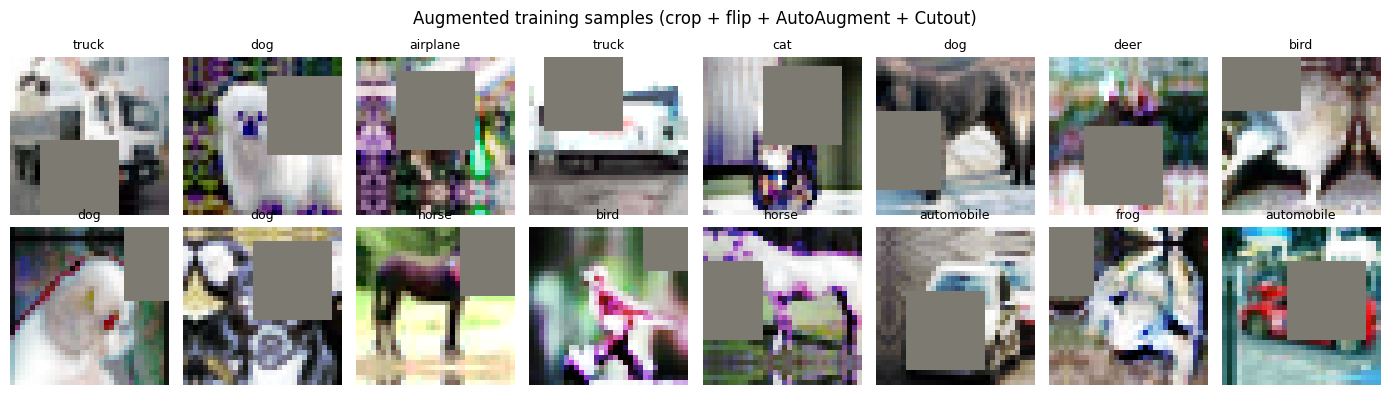

Augmentation throughput: 9,179 images/s


In [ ]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1) * 255
AUTO_AUGMENT = v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10)

def _reflect(i, n):
    i = i.abs()
    return torch.where(i > n - 1, 2 * (n - 1) - i, i)

def random_crop_flip(x, pad=4):
    # Per-image random crop from a reflect-padded image + random horizontal flip, as one gather.
    B, C, H, W = x.shape
    dy = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    dx = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    rows = _reflect(torch.arange(H, device=x.device)[None] + dy, H)            # (B, H)
    cols = _reflect(torch.arange(W, device=x.device)[None] + dx, W)            # (B, W)
    flip = torch.rand(B, 1, device=x.device) < 0.5
    cols = torch.where(flip, cols.flip(1), cols)
    b = torch.arange(B, device=x.device)[:, None, None]
    return x[b, :, rows[:, :, None], cols[:, None, :]].permute(0, 3, 1, 2)      # (B, C, H, W)

def auto_augment(x):
    # One random AutoAugment sub-policy per chunk of images.
    return torch.cat([AUTO_AUGMENT(c) for c in x.split(CFG["aa_chunk"])])

def cutout(x, size):
    # Zero (= dataset mean after normalisation) one random size x size square per image.
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    mask = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~mask).unsqueeze(1)

def normalize(x_uint8):
    return ((x_uint8.float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def augment(x_uint8):
    x = auto_augment(random_crop_flip(x_uint8).contiguous())
    x = (x.float() - MEAN) / STD
    if CFG["cutout"]:
        x = cutout(x, CFG["cutout"])
    return x.contiguous(memory_format=torch.channels_last)

def train_batches(batch_size):
    # One epoch of augmented batches (drop_last=True).
    perm = torch.randperm(len(X_train), device=device)
    for i in range(0, len(X_train) - batch_size + 1, batch_size):
        idx = perm[i:i + batch_size]
        yield augment(X_train[idx]), Y_train[idx]

# Peek at augmented training images
xb, yb = next(train_batches(16))
imgs = (xb.float() * STD + MEAN).clamp(0, 255).byte().permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lbl in zip(axes.flat, imgs, yb.tolist()):
    ax.imshow(img); ax.set_title(CLASSES[lbl], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training samples (crop + flip + AutoAugment + Cutout)"); plt.tight_layout(); plt.show()

# Throughput of the augmentation pipeline alone
torch.cuda.synchronize(); t0 = time.time(); n = 0
for xb, yb in train_batches(CFG["batch_size"]):
    n += len(xb)
    if n >= 10_000: break
torch.cuda.synchronize()
print(f"Augmentation throughput: {n / (time.time() - t0):,.0f} images/s")

## 4. Models
Both models use the **same `ResNetCIFAR` class** as the original notebook — residual blocks `ReLU(S(x) + F(x))` with
`F = conv3x3 → BN → ReLU → conv3x3 → BN` and `S` = identity or a 1×1 strided projection, three stages (32×32 → 16×16 → 8×8),
global average pooling and a linear classifier. The teacher is simply wider and deeper.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, conv_kernel=3, skip_kernel=1):
        super().__init__()
        p = conv_kernel // 2
        self.conv1 = nn.Conv2d(in_ch, out_ch, conv_kernel, stride, p, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, conv_kernel, 1, p, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, skip_kernel, stride, skip_kernel // 2, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)


class ResNetCIFAR(nn.Module):
    def __init__(self, channels=(80, 160, 320), blocks=(2, 3, 2), conv_kernel=3, skip_kernel=1, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, ch, stride, conv_kernel, skip_kernel))
                in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)          # global average pool (8x8 -> 1x1)
        self.fc = nn.Linear(in_ch, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)         # zero-init residual branch

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


def build_model(spec, seed):
    seed_everything(seed)            # identical initialisation for the baseline and the KD student
    return ResNetCIFAR(spec["channels"], spec["blocks"]).to(device).to(memory_format=torch.channels_last)

def n_params(model):
    # All parameters (= trainable parameters while training; the teacher is frozen only during distillation).
    return sum(p.numel() for p in model.parameters())

def count_macs(model):
    # Multiply-accumulates for one 32x32 image (conv + linear layers).
    macs = []
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            macs.append(out.numel() // out.shape[0] * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1])
        elif isinstance(m, nn.Linear):
            macs.append(m.in_features * m.out_features)
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32, device=device).contiguous(memory_format=torch.channels_last))
    for h in hs: h.remove()
    return sum(macs)

_s, _t = build_model(CFG["student"], CFG["seed"]), build_model(CFG["teacher"], CFG["seed"])
P_STUDENT, P_TEACHER = n_params(_s), n_params(_t)
print(f"{'model':<10}{'channels':>18}{'blocks':>12}{'params':>14}{'GMACs/img':>12}")
for name, m, spec in [("student", _s, CFG["student"]), ("teacher", _t, CFG["teacher"])]:
    print(f"{name:<10}{str(spec['channels']):>18}{str(spec['blocks']):>12}{n_params(m):>14,}{count_macs(m) / 1e9:>12.2f}")
print(f"Teacher / student parameter ratio: {P_TEACHER / P_STUDENT:.1f}x")
assert P_STUDENT <= 5_000_000, "Student exceeds the 5M parameter limit!"
assert 10 <= P_TEACHER / P_STUDENT <= 20, "Teacher should be 10-20x the student"
del _s, _t

model               channels      blocks        params   GMACs/img
student       (80, 160, 320)   (2, 3, 2)     4,798,810        0.78
teacher      (192, 384, 768)   (4, 4, 4)    52,826,314        7.86
Teacher / student parameter ratio: 11.0x


## 5. Training utilities

**Knowledge-distillation loss** (Hinton et al., 2015), with temperature $T$ and weight $\alpha$:

$$\mathcal{L}_{KD} = \alpha \, T^2 \, \mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big) + (1-\alpha)\,\mathrm{CE}(z_s, y)$$

The teacher's soft probabilities tell the student *how* classes relate (a cat image that looks a bit like a dog), which carries
much more information per image than the one-hot label. The teacher sees **exactly the same augmented image** as the student at
every step ("consistent" teaching, Beyer et al. 2022), so AutoAugment/Cutout stay fully effective.

In [ ]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)


class EMA:
    # Exponential moving average of weights and BN statistics, updated with fused foreach kernels.
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        w = 1 - min(self.decay, (1 + step) / (10 + step))
        torch._foreach_lerp_(list(self.module.parameters()), list(model.parameters()), w)
        for eb, mb in zip(self.module.buffers(), model.buffers()):
            if eb.dtype.is_floating_point:
                eb.lerp_(mb, w)
            else:
                eb.copy_(mb)


def make_optimizer(model, total_steps):
    decay, no_decay = [], []
    for p in model.parameters():
        (no_decay if p.ndim <= 1 else decay).append(p)      # no weight decay on BN parameters / biases
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}]
    kw = dict(lr=CFG["lr"], momentum=CFG["momentum"], nesterov=True)
    try:
        opt = torch.optim.SGD(groups, fused=True, **kw)
    except (TypeError, RuntimeError):
        opt = torch.optim.SGD(groups, foreach=True, **kw)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=CFG["lr"], total_steps=total_steps, pct_start=CFG["pct_start"],
        anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4)
    return opt, sched


def kd_loss(student_logits, teacher_logits, y, T, alpha):
    s, t = student_logits.float(), teacher_logits.float()
    soft = F.kl_div(F.log_softmax(s / T, 1), F.log_softmax(t / T, 1), reduction="batchmean", log_target=True) * T * T
    hard = F.cross_entropy(s, y)
    return alpha * soft + (1 - alpha) * hard


@torch.no_grad()
def predict_probs(model, X, tta=False, bs=1000):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x = normalize(X[i:i + bs])
        with autocast():
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(p)
    return torch.cat(out)


@torch.no_grad()
def evaluate(model, X, Y, tta=False):
    probs = predict_probs(model, X, tta)
    nll = F.nll_loss(torch.log(probs.clamp_min(1e-8)), Y).item()
    acc = (probs.argmax(1) == Y).float().mean().item() * 100
    return nll, acc, probs

In [ ]:
def run_phase(name, model, epochs, label_smoothing=0.0, teacher=None):
    """Train `model` (optionally distilling from `teacher`). Resumable; skipped if already finished."""
    last_path = os.path.join(CFG["ckpt_dir"], f"{name}_last.pt")
    best_path = os.path.join(CFG["ckpt_dir"], f"{name}_best.pt")
    done_path = os.path.join(CFG["ckpt_dir"], f"{name}_done.json")

    if os.path.exists(done_path):
        info = json.load(open(done_path))
        model.load_state_dict(torch.load(best_path, map_location=device)["model"])
        print(f"[{name}] already trained - loaded best checkpoint (epoch {info['best_epoch']}, val {info['best_acc']:.2f}%)")
        return model, info

    steps_per_epoch = len(X_train) // CFG["batch_size"]
    opt, sched = make_optimizer(model, epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    ema = EMA(model, CFG["ema_decay"])
    start_epoch, step, best_acc, best_epoch, best_is_ema, history = 0, 0, 0.0, 0, False, []

    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, step, history = ck["epoch"], ck["step"], ck["history"]
        best_acc, best_epoch, best_is_ema = ck["best_acc"], ck["best_epoch"], ck["best_is_ema"]
        torch.set_rng_state(ck["rng_cpu"]); torch.cuda.set_rng_state(ck["rng_cuda"])
        print(f"[{name}] resumed at epoch {start_epoch}/{epochs} (best val so far {best_acc:.2f}%)")

    fwd = torch.compile(model, mode=CFG["compile_mode"]) if CFG["use_compile"] else model
    t_fwd = None
    if teacher is not None:
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad_(False)
        t_fwd = torch.compile(teacher, mode=CFG["compile_mode"]) if CFG["use_compile"] else teacher
    T, alpha = CFG["kd_temperature"], CFG["kd_alpha"]

    print(f"[{name}] {n_params(model):,} params | {epochs} epochs x {steps_per_epoch} steps"
          + (f" | distilling from a {n_params(teacher):,}-param teacher (T={T}, alpha={alpha})" if teacher is not None else
             f" | label smoothing {label_smoothing}")
          + (" | compiling (first epoch is slower)" if CFG["use_compile"] and start_epoch == 0 else ""))

    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
        for x, y in train_batches(CFG["batch_size"]):
            with autocast():
                out = fwd(x)
                if t_fwd is not None:
                    with torch.no_grad():
                        t_out = t_fwd(x)
                    loss = kd_loss(out, t_out, y, T, alpha)
                else:
                    loss = F.cross_entropy(out.float(), y, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step); step += 1
            loss_sum += loss.detach() * x.size(0); correct += (out.argmax(1) == y).sum(); seen += x.size(0)
        epoch_time = time.time() - t0

        val_loss, val_acc, _ = evaluate(model, X_val, Y_val)
        ema_loss, ema_acc, _ = evaluate(ema.module, X_val, Y_val)
        history.append(dict(epoch=epoch + 1, lr=opt.param_groups[0]["lr"], train_loss=loss_sum.item() / seen,
                            train_acc=correct.item() / seen * 100, val_loss=val_loss, val_acc=val_acc,
                            ema_val_loss=ema_loss, ema_val_acc=ema_acc, time=epoch_time))

        if max(val_acc, ema_acc) > best_acc:
            best_acc, best_epoch, best_is_ema = max(val_acc, ema_acc), epoch + 1, ema_acc >= val_acc
            torch.save({"model": (ema.module if best_is_ema else model).state_dict(), "is_ema": best_is_ema,
                        "epoch": best_epoch, "val_acc": best_acc}, best_path)
        if (epoch + 1) % CFG["ckpt_every"] == 0 or epoch + 1 == epochs:
            torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(), "opt": opt.state_dict(),
                        "sched": sched.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch + 1, "step": step,
                        "history": history, "best_acc": best_acc, "best_epoch": best_epoch, "best_is_ema": best_is_ema,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state()}, last_path)

        recent = [h["time"] for h in history[-5:]]
        eta_min = (epochs - epoch - 1) * (sum(recent) / len(recent)) / 60
        print(f"[{name}] ep {epoch + 1:3d}/{epochs} | lr {history[-1]['lr']:.2e} | train loss {history[-1]['train_loss']:.3f} "
              f"acc {history[-1]['train_acc']:5.2f}% | val loss {val_loss:.3f} acc {val_acc:5.2f}% | "
              f"EMA val loss {ema_loss:.3f} acc {ema_acc:5.2f}% | best {best_acc:5.2f}% | {epoch_time:.0f}s | ETA {eta_min:.0f} min")

    info = dict(name=name, params=n_params(model), epochs=epochs, best_acc=best_acc, best_epoch=best_epoch,
                best_is_ema=best_is_ema, train_minutes=sum(h["time"] for h in history) / 60, history=history)
    json.dump(info, open(done_path, "w"))
    pd.DataFrame(history).to_csv(os.path.join(CFG["out_dir"], f"{name}_history.csv"), index=False)
    model.load_state_dict(torch.load(best_path, map_location=device)["model"])
    print(f"[{name}] done in {info['train_minutes']:.1f} min - best val {best_acc:.2f}% at epoch {best_epoch} "
          f"({'EMA' if best_is_ema else 'raw'} weights)")
    del opt, sched, ema, fwd, t_fwd
    torch.cuda.empty_cache()
    return model, info

## 6. Phase 1 — Student baseline (same ResNet and recipe as the original notebook)

In [ ]:
student_base = build_model(CFG["student"], CFG["seed"])
student_base, info_base = run_phase("student_baseline", student_base, CFG["epochs_student"],
                                    label_smoothing=CFG["label_smoothing_student"])

[student_baseline] 4,798,810 params | 200 epochs x 351 steps | label smoothing 0.1 | compiling (first epoch is slower)


W1102 00:28:35.746000 10446 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


[student_baseline] ep   1/200 | lr 4.26e-03 | train loss 2.157 acc 21.56% | val loss 1.858 acc 31.82% | EMA val loss 1.852 acc 33.88% | best 33.88% | 35s | ETA 115 min
[student_baseline] ep   2/200 | lr 5.05e-03 | train loss 2.057 acc 26.53% | val loss 1.742 acc 36.62% | EMA val loss 1.754 acc 36.40% | best 36.62% | 9s | ETA 71 min
[student_baseline] ep   3/200 | lr 6.35e-03 | train loss 1.986 acc 30.17% | val loss 1.656 acc 39.24% | EMA val loss 1.652 acc 40.28% | best 40.28% | 9s | ETA 57 min
[student_baseline] ep   4/200 | lr 8.15e-03 | train loss 1.935 acc 33.10% | val loss 1.535 acc 45.30% | EMA val loss 1.539 acc 44.84% | best 45.30% | 9s | ETA 49 min
[student_baseline] ep   5/200 | lr 1.04e-02 | train loss 1.858 acc 37.16% | val loss 1.469 acc 45.38% | EMA val loss 1.412 acc 50.44% | best 50.44% | 9s | ETA 45 min
[student_baseline] ep   6/200 | lr 1.32e-02 | train loss 1.791 acc 40.62% | val loss 1.328 acc 51.26% | EMA val loss 1.283 acc 55.40% | best 55.40% | 9s | ETA 28 min
[s

## 7. Phase 2 — Teacher (~53M parameters)
Trained from scratch on the same 45,000 images, same augmentation and schedule, **without** label smoothing so that its soft
predictions stay informative for distillation. The best (usually EMA) weights become the teacher.

In [ ]:
teacher = build_model(CFG["teacher"], CFG["seed"])
teacher, info_teacher = run_phase("teacher", teacher, CFG["epochs_teacher"],
                                  label_smoothing=CFG["label_smoothing_teacher"])

[teacher] 52,826,314 params | 200 epochs x 351 steps | label smoothing 0.0 | compiling (first epoch is slower)
[teacher] ep   1/200 | lr 4.26e-03 | train loss 2.084 acc 22.65% | val loss 1.813 acc 33.52% | EMA val loss 1.803 acc 34.46% | best 34.46% | 78s | ETA 260 min
[teacher] ep   2/200 | lr 5.05e-03 | train loss 1.958 acc 27.80% | val loss 1.684 acc 38.34% | EMA val loss 1.675 acc 39.48% | best 39.48% | 51s | ETA 214 min
[teacher] ep   3/200 | lr 6.35e-03 | train loss 1.866 acc 31.81% | val loss 1.557 acc 43.38% | EMA val loss 1.610 acc 41.96% | best 43.38% | 52s | ETA 198 min
[teacher] ep   4/200 | lr 8.15e-03 | train loss 1.793 acc 34.88% | val loss 1.507 acc 44.96% | EMA val loss 1.468 acc 47.76% | best 47.76% | 52s | ETA 190 min
[teacher] ep   5/200 | lr 1.04e-02 | train loss 1.713 acc 37.98% | val loss 1.319 acc 52.12% | EMA val loss 1.347 acc 52.42% | best 52.42% | 52s | ETA 185 min
[teacher] ep   6/200 | lr 1.32e-02 | train loss 1.621 acc 41.53% | val loss 1.388 acc 50.30% |

## 8. Phase 3 — Distill the teacher into the student
Same student architecture, same initial weights and same schedule as Phase 1 — the only difference is the loss, so any change
in accuracy is due to distillation.

In [ ]:
student_kd = build_model(CFG["student"], CFG["seed"])
student_kd, info_kd = run_phase("student_kd", student_kd, CFG["epochs_kd"], teacher=teacher)

[student_kd] 4,798,810 params | 200 epochs x 351 steps | distilling from a 52,826,314-param teacher (T=4.0, alpha=0.9) | compiling (first epoch is slower)
[student_kd] ep   1/200 | lr 4.26e-03 | train loss 11.989 acc 23.31% | val loss 2.109 acc 35.88% | EMA val loss 1.957 acc 36.28% | best 36.28% | 30s | ETA 100 min
[student_kd] ep   2/200 | lr 5.05e-03 | train loss 10.307 acc 33.40% | val loss 2.144 acc 45.20% | EMA val loss 1.630 acc 49.88% | best 49.88% | 23s | ETA 87 min
[student_kd] ep   3/200 | lr 6.35e-03 | train loss 8.681 acc 43.24% | val loss 2.004 acc 54.34% | EMA val loss 1.422 acc 60.42% | best 60.42% | 23s | ETA 83 min
[student_kd] ep   4/200 | lr 8.15e-03 | train loss 7.576 acc 49.51% | val loss 2.210 acc 55.88% | EMA val loss 1.256 acc 67.16% | best 67.16% | 23s | ETA 80 min
[student_kd] ep   5/200 | lr 1.04e-02 | train loss 6.608 acc 54.55% | val loss 1.321 acc 67.12% | EMA val loss 1.107 acc 71.76% | best 71.76% | 23s | ETA 78 min
[student_kd] ep   6/200 | lr 1.32e-02

## 9. Results

In [ ]:
MODELS = {"student_baseline": (student_base, info_base), "teacher": (teacher, info_teacher), "student_kd": (student_kd, info_kd)}

rows, VAL_PROBS = [], {}
for name, (m, info) in MODELS.items():
    nll, acc, _ = evaluate(m, X_val, Y_val)
    nll_tta, acc_tta, probs = evaluate(m, X_val, Y_val, tta=True)
    _, train_acc, _ = evaluate(m, X_train, Y_train)
    VAL_PROBS[name] = probs
    rows.append({"model": name, "params": n_params(m), "train acc (clean) %": round(train_acc, 2),
                 "val loss (NLL)": round(nll, 4), "val acc %": round(acc, 2), "val acc flip-TTA %": round(acc_tta, 2),
                 "best epoch": info["best_epoch"], "weights": "EMA" if info["best_is_ema"] else "raw",
                 "train time (min)": round(info["train_minutes"], 1)})
results = pd.DataFrame(rows).set_index("model")
results.to_csv(os.path.join(CFG["out_dir"], "results.csv"))
display(results)

t_pred = VAL_PROBS["teacher"].argmax(1)
for name in ["student_baseline", "student_kd"]:
    agree = (VAL_PROBS[name].argmax(1) == t_pred).float().mean().item() * 100
    print(f"{name:<17} agrees with the teacher on {agree:.2f}% of validation images")
gain = results.loc["student_kd", "val acc flip-TTA %"] - results.loc["student_baseline", "val acc flip-TTA %"]
print(f"\nDistillation gain (student_kd - student_baseline, flip-TTA): {gain:+.2f} percentage points")

,params,train acc (clean) %,val loss (NLL),val acc %,val acc flip-TTA %,best epoch,weights,train time (min)
model,,,,,,,,
student_baseline,4798810,99.92,0.1809,96.60,96.86,195,EMA,29.2
teacher,52826314,99.99,0.0883,97.38,97.24,192,raw,169.9
student_kd,4798810,99.90,0.1142,97.02,97.04,181,EMA,75.3


student_baseline  agrees with the teacher on 97.44% of validation images
student_kd        agrees with the teacher on 98.22% of validation images

Distillation gain (student_kd - student_baseline, flip-TTA): +0.18 percentage points


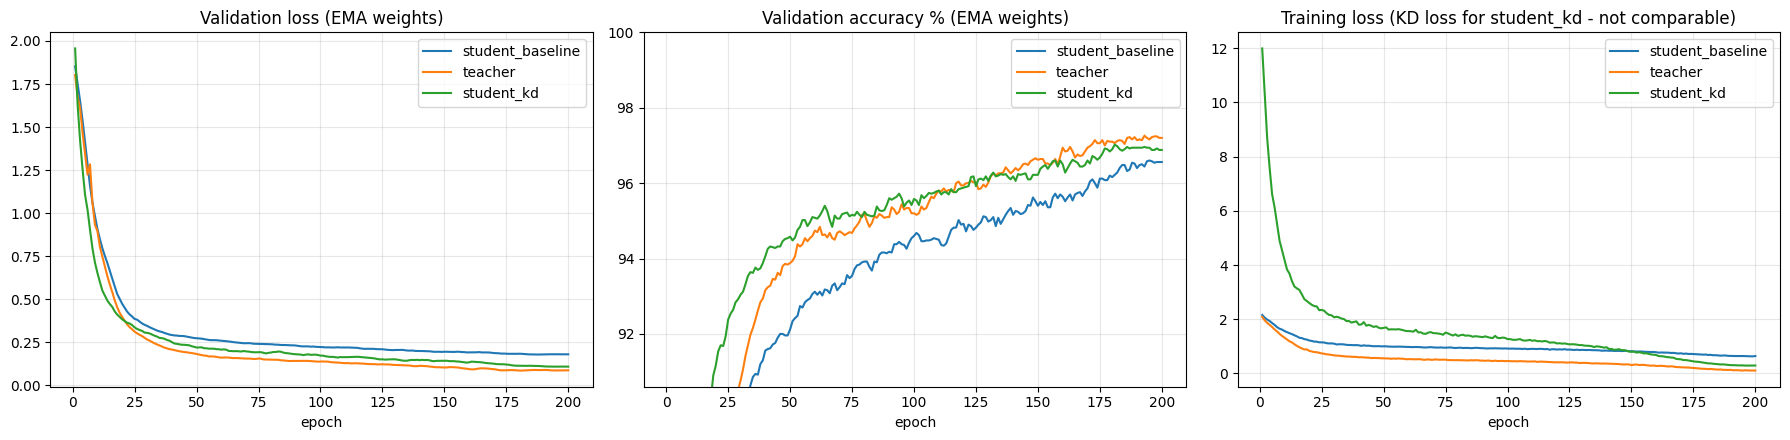

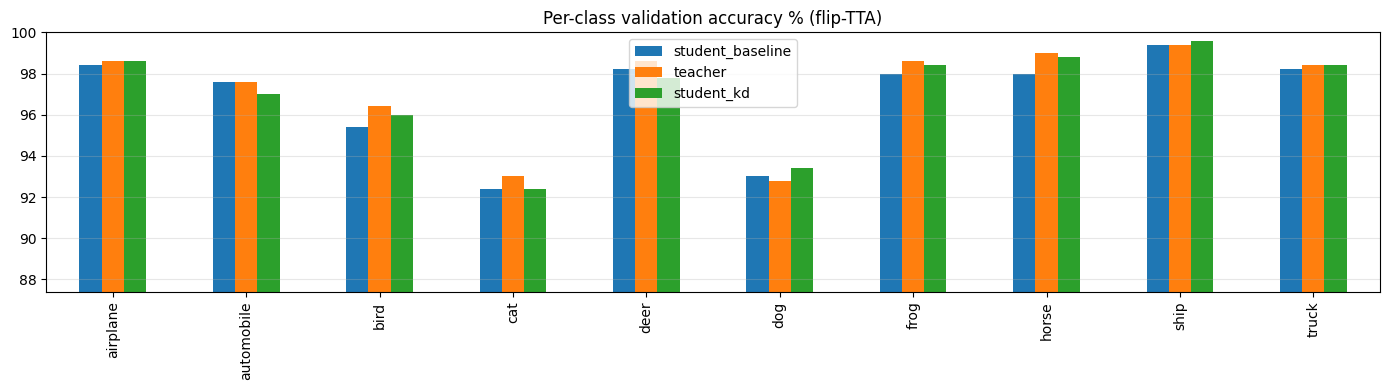

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name, (_, info) in MODELS.items():
    h = pd.DataFrame(info["history"])
    ax[0].plot(h.epoch, h.ema_val_loss, label=name)
    ax[1].plot(h.epoch, h.ema_val_acc, label=name)
    ax[2].plot(h.epoch, h.train_loss, label=name)
ax[0].set_title("Validation loss (EMA weights)"); ax[1].set_title("Validation accuracy % (EMA weights)")
ax[2].set_title("Training loss (KD loss for student_kd - not comparable)")
lo = min(pd.DataFrame(i["history"]).ema_val_acc.max() for _, i in MODELS.values()) - 6
ax[1].set_ylim(max(lo, 0), 100)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "kd_curves.png"), dpi=150); plt.show()

# Per-class validation accuracy
per_class = {}
for name, probs in VAL_PROBS.items():
    pred = probs.argmax(1)
    per_class[name] = [((pred == Y_val) & (Y_val == c)).sum().item() / max((Y_val == c).sum().item(), 1) * 100 for c in range(10)]
pc = pd.DataFrame(per_class, index=CLASSES)
pc.plot.bar(figsize=(14, 4), ylim=(max(pc.values.min() - 5, 0), 100), title="Per-class validation accuracy % (flip-TTA)")
plt.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "kd_per_class.png"), dpi=150); plt.show()

## 10. Kaggle submissions
Writes one CSV per model (flip-TTA predictions). **Only the two student files are valid competition entries** (≤ 5M parameters).
The teacher CSV is for diagnosis only. If you upload it, manually choose the final submissions on Kaggle so the teacher is
not selected.

In [ ]:
TEST_PROBS = {}
for name, (m, _) in MODELS.items():
    probs = predict_probs(m, X_test, tta=True)
    TEST_PROBS[name] = probs
    sub = pd.DataFrame({"id": test_ids, "label": probs.argmax(1).cpu().numpy()})
    path = os.path.join(CFG["out_dir"], f"submission_{name}.csv")
    sub.to_csv(path, index=False)
    np.save(os.path.join(CFG["out_dir"], f"test_probs_{name}.npy"), probs.cpu().numpy())
    note = "  <-- NOT eligible (>5M params), diagnostic only" if name == "teacher" else ""
    print(f"Wrote {path}  | predicted class counts {np.bincount(sub.label, minlength=10).tolist()}{note}")

t_test = TEST_PROBS["teacher"].argmax(1)
for name in ["student_baseline", "student_kd"]:
    agree = (TEST_PROBS[name].argmax(1) == t_test).float().mean().item() * 100
    print(f"{name:<17} agrees with the teacher on {agree:.2f}% of the Kaggle test images")

Wrote /content/drive/MyDrive/dl_project1/kd_outputs/submission_student_baseline.csv  | predicted class counts [165, 219, 204, 214, 199, 212, 181, 200, 205, 201]
Wrote /content/drive/MyDrive/dl_project1/kd_outputs/submission_teacher.csv  | predicted class counts [181, 223, 198, 206, 189, 213, 187, 205, 201, 197]  <-- NOT eligible (>5M params), diagnostic only
Wrote /content/drive/MyDrive/dl_project1/kd_outputs/submission_student_kd.csv  | predicted class counts [172, 215, 210, 195, 200, 214, 184, 200, 205, 205]
student_baseline  agrees with the teacher on 93.10% of the Kaggle test images
student_kd        agrees with the teacher on 94.50% of the Kaggle test images


## 11. Summary

In [ ]:
summary = {
    "student_architecture": f"ResNet, N=3, C={CFG['student']['channels']}, B={CFG['student']['blocks']}, F=3, K=1, global avg pool",
    "teacher_architecture": f"ResNet, N=3, C={CFG['teacher']['channels']}, B={CFG['teacher']['blocks']}, F=3, K=1, global avg pool",
    "student_params": P_STUDENT,
    "teacher_params": P_TEACHER,
    "teacher_to_student_ratio": round(P_TEACHER / P_STUDENT, 1),
    "kd": {"temperature": CFG["kd_temperature"], "alpha": CFG["kd_alpha"]},
    "results": results.reset_index().to_dict(orient="records"),
}
with open(os.path.join(CFG["out_dir"], "kd_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)

r = results.loc["student_kd"]
print(f"Teacher           : {P_TEACHER:,} params | val acc (flip-TTA) {results.loc['teacher', 'val acc flip-TTA %']:.2f}%")
print(f"Student baseline  : {P_STUDENT:,} params | val acc (flip-TTA) {results.loc['student_baseline', 'val acc flip-TTA %']:.2f}%")
print(f"Student + KD      : {P_STUDENT:,} params | val acc (flip-TTA) {r['val acc flip-TTA %']:.2f}%")
print(f"\nFINAL MODEL (student_kd): {int(r['params']):,} trainable parameters | "
      f"FINAL VALIDATION ACCURACY {r['val acc flip-TTA %']:.2f}%")

Teacher           : 52,826,314 params | val acc (flip-TTA) 97.24%
Student baseline  : 4,798,810 params | val acc (flip-TTA) 96.86%
Student + KD      : 4,798,810 params | val acc (flip-TTA) 97.04%

FINAL MODEL (student_kd): 4,798,810 trainable parameters | FINAL VALIDATION ACCURACY 97.04%
